# Compositional design of a two-input transcriptional AND circuit

This notebook treats each candidate $D_i$ as a biological implementation, not
as a label for an arbitrarily selected asymptotic regime. Two characterized
Marionette sensors provide promoter activities $(\xi_1,\xi_2)$ in relative
promoter units (RPU). Lumped expression modules produce two binding partners,
which form a catalytic complex and generate one output transcription flux.

The model is
\[
\Sigma_1:\xi_1\mapsto Y_1,\qquad
\Sigma_2:\xi_2\mapsto Y_2,
\]
\[
Y_1+Y_2\rightleftharpoons C_3,
\qquad C_3\longrightarrow C_3+P,
\qquad y=\dot P=k_{\rm out}C_3.
\]
At quasi-steady binding,
\[
K C_3=(Y_{1,\rm tot}-C_3)(Y_{2,\rm tot}-C_3).
\]
The product-forming step is coarse grained: transcriptional resources are
implicit and neither input component is asserted to be chemically converted
into the reporter product.

In [1]:
import math
import os
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", str(Path.cwd() / ".matplotlib"))

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import FancyArrowPatch, Patch, Rectangle
import numpy as np
import pandas as pd

from compositional_regime_contracts import (
    CORES,
    DEFAULT_UNCERTAINTY,
    MARIONETTE_SENSORS,
    REDESIGNS,
    REDESIGN_PARAMETERS,
    condition_flux_interval,
    infer_regime,
    make_candidate_designs,
    make_top_level_conditions,
    parameter_range_flux_bounds,
    redesigned_condition_flux_interval,
    redesigned_parameter_range_flux_bounds,
    sensor_activity,
    summarize_candidate_envelopes,
    summarize_redesigned_envelopes,
    verify_condition,
    verify_redesigned_condition,
)

pd.set_option("display.max_colwidth", 80)
candidates = make_candidate_designs()

## Characterized sensor interfaces

The aTc and Cuma entries below are transcribed from the Marionette sensor table
used in the Pacti case study, based on Meyer *et al.* (2019). Their physical
inducer concentrations are different, but each sensor exposes the same circuit
interface: output-promoter activity in RPU. No coordinate normalization by an
operating point or kinetic constant is performed.

In [2]:
sensor_rows = []
for sensor in MARIONETTE_SENSORS.values():
    sensor_rows.append({
        "Sensor": sensor.name,
        "Promoter": sensor.promoter,
        "Regulator": sensor.regulator,
        "leak [RPU]": sensor.leak_rpu,
        "K [uM]": sensor.half_max_uM,
        "Hill n": sensor.hill_n,
        "measured max [RPU]": sensor.max_rpu,
        "validated linear max [RPU]": sensor.linear_max_rpu,
    })
sensor_table = pd.DataFrame(sensor_rows)
sensor_table

,Sensor,Promoter,Regulator,leak [RPU],K [uM],Hill n,measured max [RPU],validated linear max [RPU]
0,aTc,PTet*,TetR,0.0049,0.013,3.8,2.4,1.0
1,Cuma,PCymRC,CymRAM,0.0043,8.900,2.4,3.7,2.0


## Integration cores and provisional design ranges

The three architectures are literature-backed. The effective affinities,
promoter-to-component gains, and output rates below are **provisional nominal
values**, not measurements reported by those papers. They place all three
architectures in a common coarse-grained unit system for this methodology
example. The uncertainty factors are deliberately varied around the nominals;
they will be replaced by measured ranges in a later parameterization pass.

In [3]:
core_rows = []
for core in CORES:
    core_rows.append({
        "Core": core.name,
        "Input 1": core.component_1,
        "Input 2": core.component_2,
        "Output promoter": core.output_promoter,
        "K nominal [nM]": core.affinity_nM,
        "k_out nominal [1/min]": core.output_rate_per_min,
        "g1 [nM/RPU]": core.gain_1_nM_per_rpu,
        "g2 [nM/RPU]": core.gain_2_nM_per_rpu,
        "center regime": core.nominal_regime,
    })
core_table = pd.DataFrame(core_rows)
display(core_table)

uncertainty_table = pd.DataFrame([
    {"Parameter class": "lumped expression gains", "Range": f"nominal / {DEFAULT_UNCERTAINTY['gain_fold']} to nominal x {DEFAULT_UNCERTAINTY['gain_fold']}"},
    {"Parameter class": "effective affinity", "Range": f"nominal / {DEFAULT_UNCERTAINTY['affinity_fold']} to nominal x {DEFAULT_UNCERTAINTY['affinity_fold']}"},
    {"Parameter class": "output rate", "Range": f"nominal / {DEFAULT_UNCERTAINTY['output_rate_fold']} to nominal x {DEFAULT_UNCERTAINTY['output_rate_fold']}"},
])
display(uncertainty_table)

,Core,Input 1,Input 2,Output promoter,K nominal [nM],k_out nominal [1/min],g1 [nM/RPU],g2 [nM/RPU],center regime
0,HrpR/HrpS,HrpR,HrpS,PhrpL,250.0,1.2,4000.0,800.0,input 1 excess
1,split T7 RNAP,T7 RNAP N fragment,T7 RNAP C fragment,PT7,1200.0,10.0,500.0,700.0,affinity-dominated
2,InvF/SicA,InvF,SicA,PsicA,250.0,1.0,800.0,4000.0,input 2 excess


,Parameter class,Range
0,lumped expression gains,nominal / 1.25 to nominal x 1.25
1,effective affinity,nominal / 1.3 to nominal x 1.3
2,output rate,nominal / 1.25 to nominal x 1.25


## Candidate designs

Each integration core is paired with both ordered assignments of aTc and Cuma.
Ordering changes the physical inducer-to-promoter map even when two candidates
have the same contract after the RPU interface. This is an intended example of
interface abstraction: downstream verification can be reused while the
physical sensor implementation changes.

In [4]:
design_rows = []
for candidate in candidates:
    design_rows.append({
        "Design": candidate.name,
        "Core": candidate.core.name,
        "Sensor -> input 1": f"{candidate.sensor_1.name} -> {candidate.core.component_1}",
        "Sensor -> input 2": f"{candidate.sensor_2.name} -> {candidate.core.component_2}",
        "Regime at xi=(0.5,0.5)": infer_regime(candidate, 0.5, 0.5),
    })
design_table = pd.DataFrame(design_rows)
design_table

,Design,Core,Sensor -> input 1,Sensor -> input 2,"Regime at xi=(0.5,0.5)"
0,D1,HrpR/HrpS,aTc -> HrpR,Cuma -> HrpS,input 1 excess
1,D2,HrpR/HrpS,Cuma -> HrpR,aTc -> HrpS,input 1 excess
2,D3,split T7 RNAP,aTc -> T7 RNAP N fragment,Cuma -> T7 RNAP C fragment,affinity-dominated
3,D4,split T7 RNAP,Cuma -> T7 RNAP N fragment,aTc -> T7 RNAP C fragment,affinity-dominated
4,D5,InvF/SicA,aTc -> InvF,Cuma -> SicA,input 2 excess
5,D6,InvF/SicA,Cuma -> InvF,aTc -> SicA,input 2 excess


## Top-level AND-gate specification

The desired AND behavior contains one ON region and two OFF regions:
\[
(\xi_1,\xi_2)\in B_{\rm ON}\Longrightarrow y\ge y_{\rm ON},
\]
\[
\xi_1\in B_{\rm OFF}\ \text{or}\ \xi_2\in B_{\rm OFF}
\Longrightarrow y\le y_{\rm OFF}.
\]
The input regions are stated in promoter activity units. The ON region lies inside
the experimentally useful Marionette RPU range. The OFF interval begins near
the characterized leak floors and extends to 20% of the ON onset; the interval
from 0.07 to 0.35 RPU is deliberately unspecified as a transition region. The
round exploratory flux targets impose a twofold output separation. In an
experimental design, these levels would be set from measured sensor variation
and the activation and burden limits of the downstream receiver.

In [5]:
conditions = make_top_level_conditions()
envelope_summary = summarize_candidate_envelopes(candidates, conditions)
condition_table = pd.DataFrame([
    {
        "Condition": condition.name,
        "xi1 [RPU]": condition.xi1_bounds,
        "xi2 [RPU]": condition.xi2_bounds,
        "Required flux": (
            f">= {condition.flux_threshold:.2f} nM/min"
            if condition.guarantee_kind == "lower"
            else f"<= {condition.flux_threshold:.2f} nM/min"
        ),
    }
    for condition in conditions
])
display(pd.DataFrame({
    "Core": envelope_summary["on_floors"].keys(),
    "worst-case ON floor [nM/min]": envelope_summary["on_floors"].values(),
    "worst-case OFF ceiling [nM/min]": envelope_summary["off_ceilings"].values(),
}))
display(condition_table)

,Core,worst-case ON floor [nM/min],worst-case OFF ceiling [nM/min]
0,HrpR/HrpS,160.353080,357.785368
1,split T7 RNAP,116.678124,226.628228
2,InvF/SicA,133.627566,298.154473


,Condition,xi1 [RPU],xi2 [RPU],Required flux
0,ON,"(0.35, 0.65)","(0.35, 0.65)",>= 120.00 nM/min
1,OFF-1,"(0.0055, 0.07)","(0.35, 0.65)",<= 60.00 nM/min
2,OFF-2,"(0.35, 0.65)","(0.0055, 0.07)",<= 60.00 nM/min


## Composition and formal checks

For a finite operating region, the catalytic-core contract uses the globally valid
bounds
\[
\frac{Y_1Y_2}{K+Y_1+Y_2}\le C_3
\le\min\left\{Y_1,Y_2,\frac{Y_1Y_2}{K}\right\}.
\]
Monotonic endpoint bounds tighten this contract over each region. Parameter-range
endpoints are incorporated before composing the two lumped expression
contracts with the core contract. A design implements the complete AND
specification only if it refines the ON, OFF-1, and OFF-2 contracts.

The top-level object is therefore the mode-indexed family
\[
\mathfrak C_{\rm spec}=\{\mathcal C_{\rm ON},
\mathcal C_{\rm OFF,1},\mathcal C_{\rm OFF,2}\},
\qquad
D\models\mathfrak C_{\rm spec}
\Longleftrightarrow
\bigwedge_q \mathcal C_D^q\preceq\mathcal C_{\rm spec}^q.
\]
An ordinary Pacti merge is not used: it would conjoin the mutually exclusive
mode assumptions instead of preserving the three conditional requirements.

In [6]:
verification_rows = []
verification = {}
for candidate in candidates:
    condition_results = {}
    for condition in conditions:
        result = verify_condition(candidate, condition)
        condition_results[condition.name] = result
    verification[candidate.name] = condition_results
    verification_rows.append({
        "Design": candidate.name,
        "Core": candidate.core.name,
        "Sensors (input 1, input 2)": f"({candidate.sensor_1.name}, {candidate.sensor_2.name})",
        "A_ON subset A_D": condition_results["ON"]["assumptions"],
        "G_D implies G_ON": condition_results["ON"]["guarantees"],
        "A_OFF,1 subset A_D": condition_results["OFF-1"]["assumptions"],
        "G_D implies G_OFF,1": condition_results["OFF-1"]["guarantees"],
        "A_OFF,2 subset A_D": condition_results["OFF-2"]["assumptions"],
        "G_D implies G_OFF,2": condition_results["OFF-2"]["guarantees"],
        "Full AND refinement": all(result["refines"] for result in condition_results.values()),
    })
verification_table = pd.DataFrame(verification_rows)
verification_table

,Design,Core,"Sensors (input 1, input 2)",A_ON subset A_D,G_D implies G_ON,"A_OFF,1 subset A_D","G_D implies G_OFF,1","A_OFF,2 subset A_D","G_D implies G_OFF,2",Full AND refinement
0,D1,HrpR/HrpS,"(aTc, Cuma)",True,True,True,False,True,False,False
1,D2,HrpR/HrpS,"(Cuma, aTc)",True,True,True,False,True,False,False
2,D3,split T7 RNAP,"(aTc, Cuma)",True,False,True,False,True,False,False
3,D4,split T7 RNAP,"(Cuma, aTc)",True,False,True,False,True,False,False
4,D5,InvF/SicA,"(aTc, Cuma)",True,True,True,False,True,False,False
5,D6,InvF/SicA,"(Cuma, aTc)",True,True,True,False,True,False,False


In [7]:
interval_rows = []
for candidate in candidates[::2]:
    row = {"Core": candidate.core.name}
    for condition in conditions:
        lo, hi = condition_flux_interval(
            candidate, condition.xi1_bounds, condition.xi2_bounds
        )
        row[condition.name] = f"[{lo:.1f}, {hi:.1f}]"
    interval_rows.append(row)
pd.DataFrame(interval_rows)

,Core,ON,OFF-1,OFF-2
0,HrpR/HrpS,"[160.4, 908.9]","[6.8, 357.8]","[2.6, 99.0]"
1,split T7 RNAP,"[116.7, 1634.2]","[2.0, 204.7]","[2.0, 226.6]"
2,InvF/SicA,"[133.6, 757.4]","[2.2, 82.5]","[5.6, 298.2]"


### Initial design insight

The broadened LOW range exposes a limitation that the leak-only specification
hid: none of the three direct complex-formation cores guarantees the complete
AND behavior. HrpR/HrpS and InvF/SicA reach the ON target but exceed the OFF
ceiling; split T7 RNAP also falls slightly below the ON target. The equality of
each ordered pair after the RPU interface still shows what the abstraction
provides; their required inducer concentrations remain different in the sensor
contracts.

## Mechanism-specific redesigns from published biology

The fixed top-level specification remains unchanged. Each redesign introduces
one mechanism with a literature basis:

1. **HrpR/HrpS + HrpV inhibition.** Jovanovic *et al.* directly assayed
   HrpV inhibition of HrpRS, using $0.8\,\mu\mathrm{M}$ HrpRS and HrpV doses
   from $0.1$ to $0.8\,\mu\mathrm{M}$. The redesigned model therefore adds a
   constitutive HrpV pool over that experimentally assayed range. In the
   absence of a reported HrpV--HrpS dissociation constant, the implementation
   uses a stoichiometric strong-inhibition abstraction: one HrpV unit can
   neutralize one unit of productive HrpRS complex.
2. **split T7 RNAP + SYNZIP17/18.** The residue-601 split was fused to
   SYNZIP17 and SYNZIP18 to promote fragment complementation. The measured
   SYNZIP17:SYNZIP18 interaction has $K_d<10\,\mathrm{nM}$, so the redesign
   replaces the provisional $1200\,\mathrm{nM}$ affinity by the conservative
   interval $0<K\le 10\,\mathrm{nM}$. The existing gain and output-rate ranges
   are left unchanged.
3. **InvF/SicA + native SicA--SipC titration.** The mechanistic model of
   Temme *et al.* uses $K_{XY}=1700\,\mathrm{nM}$ for InvF:SicA,
   $K_{YZ}=28\,\mathrm{nM}$ for SicA:SipC, and approximately 6000--10000 SipC
   molecules/cell. SicA first equilibrates with the fixed SipC pool, then free
   SicA can form the active InvF:SicA complex.

These are forward evaluations of literature-motivated mechanism changes.
Parameters are not searched or adjusted to force refinement.

In [ ]:
redesign_rows = []
for core_name, redesign in REDESIGNS.items():
    params = REDESIGN_PARAMETERS[core_name]
    redesign_rows.append({
        "Core": core_name,
        "Redesign": redesign.label,
        "Mechanism": redesign.mechanism,
        "Literature parameters used": str(params),
        "Source": redesign.source,
    })
pd.DataFrame(redesign_rows)

In [ ]:
redesigned_envelope_summary = summarize_redesigned_envelopes(candidates, conditions)

redesigned_verification_rows = []
redesigned_verification = {}
for candidate in candidates:
    condition_results = {}
    for condition in conditions:
        result = verify_redesigned_condition(candidate, condition)
        condition_results[condition.name] = result
    redesigned_verification[candidate.name] = condition_results
    redesigned_verification_rows.append({
        "Design": candidate.name,
        "Core": candidate.core.name,
        "Redesign": REDESIGNS[candidate.core.name].label,
        "Sensors (input 1, input 2)": f"({candidate.sensor_1.name}, {candidate.sensor_2.name})",
        "ON": condition_results["ON"]["refines"],
        "OFF-1": condition_results["OFF-1"]["refines"],
        "OFF-2": condition_results["OFF-2"]["refines"],
        "Full AND refinement": all(result["refines"] for result in condition_results.values()),
    })
redesigned_verification_table = pd.DataFrame(redesigned_verification_rows)
display(redesigned_verification_table)

redesigned_interval_rows = []
for candidate in candidates[::2]:
    row = {
        "Core": candidate.core.name,
        "Redesign": REDESIGNS[candidate.core.name].label,
    }
    for condition in conditions:
        lo, hi = redesigned_condition_flux_interval(
            candidate, condition.xi1_bounds, condition.xi2_bounds
        )
        row[condition.name] = f"[{lo:.3g}, {hi:.3g}]"
    redesigned_interval_rows.append(row)
pd.DataFrame(redesigned_interval_rows)

## Desired regions and candidate guarantees

All panels use the actual promoter activities $(\xi_1,\xi_2)$ in RPU on
logarithmic axes; the coordinates are not divided by an operating point or by
a kinetic constant. The first panel states the required environments and the
common characterized sensor-admissible domain for all six designs.
The other panels shade where each biological core guarantees the ON floor or
the OFF ceiling over the stated parameter ranges. Curved shaded boundaries
come from the full QSS binding relation rather than from artificial rectangular
design regions.

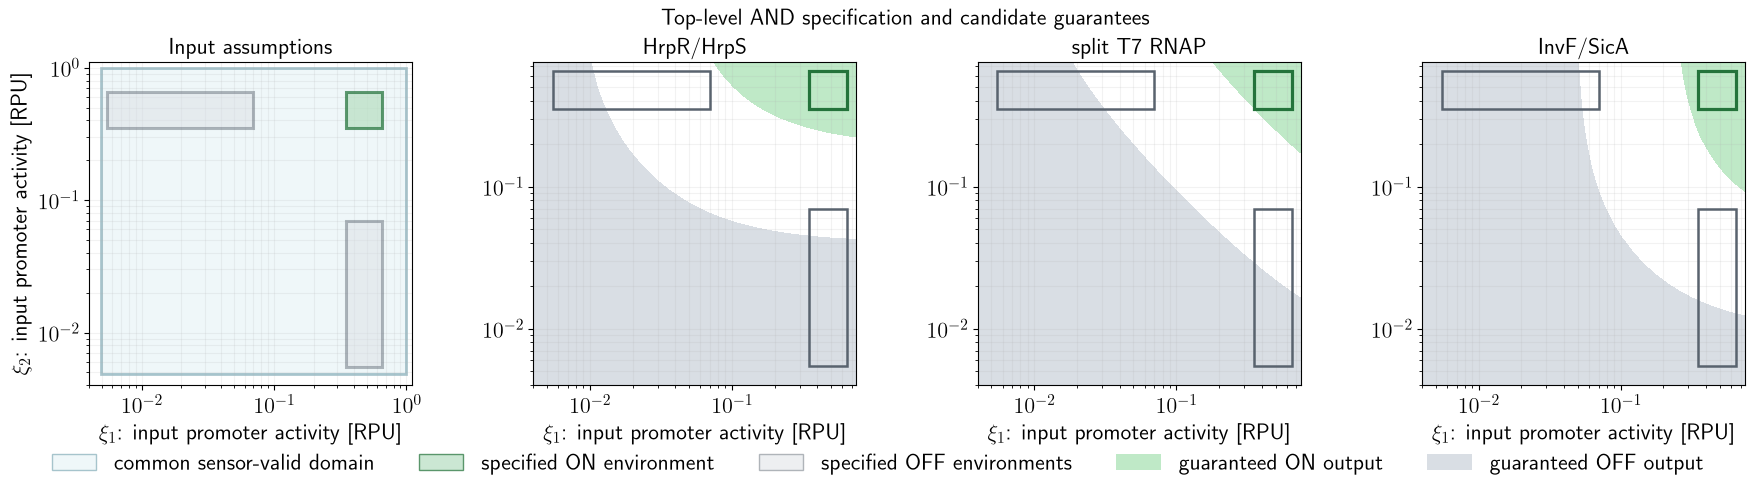

In [8]:
plt.rcParams.update({
    "text.usetex": True,
    "text.latex.preamble": r"\usepackage{amsfonts,amssymb}",
    "font.size": 16,
    "axes.labelsize": 16,
    "axes.titlesize": 16,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "legend.fontsize": 16,
})
on_condition = next(c for c in conditions if c.name == "ON")
off1_condition = next(c for c in conditions if c.name == "OFF-1")
off2_condition = next(c for c in conditions if c.name == "OFF-2")

xi = np.geomspace(0.004, 0.75, 320)
XI1, XI2 = np.meshgrid(xi, xi)

representatives = {}
for candidate in candidates:
    representatives.setdefault(candidate.core.name, candidate)

fig, axes = plt.subplots(1, 4, figsize=(18.0, 4.9), constrained_layout=True)
ax_assume = axes[0]

def add_region(ax, x_bounds, y_bounds, face, edge, label=None, alpha=0.45, lw=2.2, zorder=5):
    patch = Rectangle(
        (x_bounds[0], y_bounds[0]),
        x_bounds[1] - x_bounds[0],
        y_bounds[1] - y_bounds[0],
        facecolor=face,
        edgecolor=edge,
        linewidth=lw,
        alpha=alpha,
        label=label,
        zorder=zorder,
    )
    ax.add_patch(patch)
    return patch

common_sensor_low = max(sensor.leak_rpu for sensor in MARIONETTE_SENSORS.values())
common_sensor_high = min(sensor.linear_max_rpu for sensor in MARIONETTE_SENSORS.values())
add_region(
    ax_assume,
    (common_sensor_low, common_sensor_high),
    (common_sensor_low, common_sensor_high),
    "#d9edf2",
    "#39798a",
    alpha=0.42,
    lw=2.0,
    zorder=1,
)
add_region(
    ax_assume,
    on_condition.xi1_bounds,
    on_condition.xi2_bounds,
    "#b8dfc2",
    "#24733b",
    r"$A_{\mathrm{ON}}$",
    alpha=0.72,
)
add_region(
    ax_assume,
    off1_condition.xi1_bounds,
    off1_condition.xi2_bounds,
    "#d9dde2",
    "#59636e",
    r"$A_{\mathrm{OFF},1}$",
)
add_region(
    ax_assume,
    off2_condition.xi1_bounds,
    off2_condition.xi2_bounds,
    "#d9dde2",
    "#59636e",
)

ax_assume.set_title(r"Input assumptions", fontweight="bold")

for ax, (core_name, candidate) in zip(axes[1:], representatives.items()):
    lower, upper = parameter_range_flux_bounds(candidate, XI1, XI2)
    ax.contourf(
        XI1, XI2, upper <= off1_condition.flux_threshold,
        levels=[0.5, 1.5], colors=["#cfd5dd"], alpha=0.78
    )
    ax.contourf(
        XI1, XI2, lower >= on_condition.flux_threshold,
        levels=[0.5, 1.5], colors=["#79d18b"], alpha=0.48
    )
    add_region(
        ax,
        on_condition.xi1_bounds,
        on_condition.xi2_bounds,
        "none",
        "#24733b",
        alpha=1.0,
        lw=2.3,
    )
    add_region(
        ax,
        off1_condition.xi1_bounds,
        off1_condition.xi2_bounds,
        "none",
        "#59636e",
        alpha=1.0,
        lw=1.8,
    )
    add_region(
        ax,
        off2_condition.xi1_bounds,
        off2_condition.xi2_bounds,
        "none",
        "#59636e",
        alpha=1.0,
        lw=1.8,
    )
    ax.set_title(core_name, fontweight="bold")

for ax in axes:
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(0.004, 0.75)
    ax.set_ylim(0.004, 0.75)
    ax.set_xlabel(r"$\xi_1$: input promoter activity [RPU]")
    ax.grid(which="both", alpha=0.16)
    ax.set_aspect("equal", adjustable="box")
    ax.tick_params(axis="both", which="both", labelsize=16)
axes[0].set_ylabel(r"$\xi_2$: input promoter activity [RPU]")
axes[0].set_xlim(0.004, 1.1)
axes[0].set_ylim(0.004, 1.1)

handles = [
    Patch(facecolor="#d9edf2", edgecolor="#39798a", alpha=0.42,
          label="common sensor-valid domain"),
    Patch(facecolor="#b8dfc2", edgecolor="#24733b", alpha=0.72,
          label="specified ON environment"),
    Patch(facecolor="#d9dde2", edgecolor="#59636e", alpha=0.45,
          label="specified OFF environments"),
    Patch(facecolor="#79d18b", edgecolor="none", alpha=0.48,
          label="guaranteed ON output"),
    Patch(facecolor="#cfd5dd", edgecolor="none", alpha=0.78,
          label="guaranteed OFF output"),
]
fig.legend(
    handles=handles,
    loc="outside lower center",
    ncol=5,
    frameon=False,
)

fig.suptitle("Top-level AND specification and candidate guarantees", fontsize=16, fontweight="bold")
output_base = Path("compositional_operating_region_summary")
fig.savefig(output_base.with_suffix(".png"), dpi=230, bbox_inches="tight")
fig.savefig(output_base.with_suffix(".pdf"), bbox_inches="tight")
plt.show()

## What the heatmap shading means

For each mode $q\in\{\mathrm{ON},\mathrm{OFF\!-\!1},\mathrm{OFF\!-\!2}\}$, the
conditional specification is
\[
\mathcal{C}_{\mathrm{spec}}^q=(A_q,G_q).
\]
Here $A_q$ is a set of allowed input promoter activities and $G_q$ is the
required output-flux inequality for that mode. They are sets in different
spaces, so an assumption is not literally contained in a guarantee. The plot
instead shades the projected input satisfaction set
\[
S_D^q=\{\xi:\ y_D(\xi;\theta)\text{ satisfies }G_q
\text{ for every allowed }\theta\}.
\]
A design passes mode $q$ when $A_q\subseteq S_D^q$: every allowed input in
that mode produces outputs satisfying its output requirement. In the heatmap,
the green outline is $A_{\mathrm{ON}}$ and the green shading is
$S_D^{\mathrm{ON}}$; the gray outlines are the two OFF assumptions and the gray
shading is the common set where the OFF ceiling is guaranteed.

## Initial designs and mechanism-specific redesigns

Each column follows one biological architecture from its initial design in the
top row to its literature-grounded redesign in the bottom row. The outlined ON
and OFF regions are the same fixed top-level requirement in every panel:
$y\ge 120\,\mathrm{nM/min}$ in the ON region and
$y\le 60\,\mathrm{nM/min}$ in either OFF region. The arrow between rows states
the mechanism change used for that architecture.

Color gives the worst-case lower output flux over the stated parameter ranges.
Green shading marks inputs where the ON floor is guaranteed, and gray shading
marks inputs where the OFF ceiling is guaranteed. Thick white contours show
the two output thresholds: solid for ON and dashed for OFF.

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16.8, 11.0))
fig.subplots_adjust(
    left=0.075, right=0.89, top=0.88, bottom=0.16,
    wspace=0.28, hspace=0.62,
)

last_mesh = None
vmax = max(
    max(envelope_summary["on_floors"].values()),
    max(redesigned_envelope_summary["on_floors"].values()),
) * 1.8

def draw_flux_panel(ax, lower, upper, title):
    mesh = ax.pcolormesh(
        XI1, XI2, lower, shading="auto", cmap="viridis", vmin=0, vmax=vmax,
    )
    ax.contourf(
        XI1, XI2, upper <= off1_condition.flux_threshold,
        levels=[0.5, 1.5], colors=["#cfd5dd"], alpha=0.42
    )
    ax.contourf(
        XI1, XI2, lower >= on_condition.flux_threshold,
        levels=[0.5, 1.5], colors=["#79d18b"], alpha=0.30
    )
    if np.nanmin(upper) <= off1_condition.flux_threshold <= np.nanmax(upper):
        ax.contour(
            XI1, XI2, upper,
            levels=[off1_condition.flux_threshold], colors=["white"],
            linewidths=4.0, linestyles="dashed", zorder=4,
        )
    if np.nanmin(lower) <= on_condition.flux_threshold <= np.nanmax(lower):
        ax.contour(
            XI1, XI2, lower,
            levels=[on_condition.flux_threshold], colors=["white"],
            linewidths=4.0, linestyles="solid", zorder=4,
        )
    add_region(
        ax, on_condition.xi1_bounds, on_condition.xi2_bounds,
        "none", "#79d18b", alpha=1.0, lw=2.2
    )
    add_region(
        ax, off1_condition.xi1_bounds, off1_condition.xi2_bounds,
        "none", "#d9dde2", alpha=1.0, lw=1.4
    )
    add_region(
        ax, off2_condition.xi1_bounds, off2_condition.xi2_bounds,
        "none", "#d9dde2", alpha=1.0, lw=1.4
    )
    ax.set_title(title, fontsize=16, fontweight="bold")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(0.004, 0.75)
    ax.set_ylim(0.004, 0.75)
    ax.set_xlabel(r"$\xi_1$ [RPU]")
    ax.set_ylabel(r"$\xi_2$ [RPU]")
    ax.grid(which="both", alpha=0.12)
    ax.tick_params(axis="both", which="both", labelsize=16)
    return mesh

for col, (core_name, candidate) in enumerate(representatives.items()):
    lower, upper = parameter_range_flux_bounds(candidate, XI1, XI2)
    last_mesh = draw_flux_panel(axes[0, col], lower, upper, core_name)

    lower_new, upper_new = redesigned_parameter_range_flux_bounds(
        candidate, XI1, XI2
    )
    last_mesh = draw_flux_panel(axes[1, col], lower_new, upper_new, core_name)

redesign_caption = {
    "HrpR/HrpS": (
        r"add HrpV inhibition" + "\n" +
        r"$0.1$--$0.8\,\mu\mathrm{M}$ HrpV"
    ),
    "split T7 RNAP": (
        r"add SYNZIP17/18" + "\n" +
        r"$K_d<10\,\mathrm{nM}$"
    ),
    "InvF/SicA": (
        r"add SicA--SipC titration" + "\n" +
        r"$K_{YZ}=28\,\mathrm{nM}$; 6000--10000 SipC/cell"
    ),
}

fig.canvas.draw()
for col, core_name in enumerate(representatives):
    top_box = axes[0, col].get_position()
    bottom_box = axes[1, col].get_position()
    x_mid = 0.5 * (top_box.x0 + top_box.x1)
    y_start = top_box.y0 - 0.012
    y_end = bottom_box.y1 + 0.012
    arrow = FancyArrowPatch(
        (x_mid, y_start),
        (x_mid, y_end),
        transform=fig.transFigure,
        arrowstyle="-|>",
        mutation_scale=18,
        linewidth=1.5,
        clip_on=False,
    )
    fig.add_artist(arrow)
    fig.text(
        x_mid,
        0.5 * (y_start + y_end),
        redesign_caption[core_name],
        ha="center",
        va="center",
        fontsize=12,
        bbox={"facecolor": "white", "edgecolor": "none", "pad": 1.5},
    )

fig.text(
    0.018, 0.675, "Initial designs",
    rotation=90, va="center", ha="center",
    fontsize=16, fontweight="bold",
)
fig.text(
    0.018, 0.305, "Mechanism-specific redesigns",
    rotation=90, va="center", ha="center",
    fontsize=16, fontweight="bold",
)
fig.suptitle(
    "Fixed AND requirement across initial and redesigned architectures",
    fontsize=16,
    fontweight="bold",
)
fig.text(
    0.5, 0.91,
    r"ON: $y\ge 120\,\mathrm{nM/min}$; OFF: $y\le 60\,\mathrm{nM/min}$",
    ha="center",
    va="center",
    fontsize=14,
)

cbar = fig.colorbar(last_mesh, ax=axes.ravel().tolist(), shrink=0.82, pad=0.025)
cbar.set_label("worst-case lower output flux [nM/min]")
cbar.ax.tick_params(labelsize=16)

legend = [
    Patch(facecolor="#79d18b", edgecolor="#79d18b", alpha=0.30,
          label="guaranteed ON output"),
    Patch(facecolor="#cfd5dd", edgecolor="#cfd5dd", alpha=0.42,
          label="guaranteed OFF output"),
    Patch(facecolor="none", edgecolor="#79d18b",
          label="specified ON environment"),
    Patch(facecolor="none", edgecolor="#777777",
          label="specified OFF environments"),
    Line2D([0], [0], color="#444444", linewidth=4.0, linestyle="solid",
           label="ON threshold"),
    Line2D([0], [0], color="#444444", linewidth=4.0, linestyle="dashed",
           label="OFF threshold"),
]
fig.legend(
    handles=legend,
    loc="lower center",
    bbox_to_anchor=(0.49, 0.035),
    ncol=3,
    frameon=False,
)

output_base = Path("compositional_design_flux_maps")
fig.savefig(output_base.with_suffix(".png"), dpi=230, bbox_inches="tight")
fig.savefig(output_base.with_suffix(".pdf"), bbox_inches="tight")
plt.show()

## Interpretation

- The desired assumptions are finite ON/OFF regions.
- The desired guarantee has physical meaning: a minimum transcription flux in
  the ON region and a maximum leak flux in either OFF region.
- Curved design boundaries are induced by the QSS complex relation and
  parameter ranges.
- Ordered Marionette sensor assignments differ before the RPU interface and
  deliberately share downstream verification results.
- The upper row shows the unchanged initial designs; the lower row shows the
  approved mechanism-specific redesigns under the same fixed requirement.
- The arrow between each pair of panels states the single mechanism change
  introduced for that architecture.
- Redesigned candidates are reported as passes or failures directly. No
  redesign parameter is adjusted after seeing the refinement result.